In [4]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("Libraries imported successfully.")

Libraries imported successfully.


In [5]:
file_path = "C:/Users/RSCH/Desktop/DWD/Final project/Retail-Intelligence-Platform/datasets/customer_rfm.xlsx"

rfm = pd.read_excel(
    file_path,
    sheet_name="RFM_Analysis"
)

rfm.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total,RFM_Segment
0,0025d7a1-81d7-4240-8807-4aed48f88cde,153,1,258142.0,2,1,4,214,7,Potential
1,00381394-0d27-43e1-aa0c-2105ea482b2b,184,1,396249.0,1,1,5,115,7,Potential
2,003c8473-1b85-445f-bcfb-948e6c9f8451,100,1,375593.0,3,1,5,315,9,Potential
3,004d5aa3-b784-4619-8e18-0411b8f90404,70,1,162866.0,4,1,2,412,7,Potential
4,0089210b-880d-4835-b385-14486458934b,88,1,278088.0,3,1,4,314,8,Potential


In [6]:
print("Rows:", len(rfm))
print("Columns:", len(rfm.columns))

rfm.head()

Rows: 2464
Columns: 10


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total,RFM_Segment
0,0025d7a1-81d7-4240-8807-4aed48f88cde,153,1,258142.0,2,1,4,214,7,Potential
1,00381394-0d27-43e1-aa0c-2105ea482b2b,184,1,396249.0,1,1,5,115,7,Potential
2,003c8473-1b85-445f-bcfb-948e6c9f8451,100,1,375593.0,3,1,5,315,9,Potential
3,004d5aa3-b784-4619-8e18-0411b8f90404,70,1,162866.0,4,1,2,412,7,Potential
4,0089210b-880d-4835-b385-14486458934b,88,1,278088.0,3,1,4,314,8,Potential


In [7]:
print("Rows:", len(rfm))
print("Columns:", len(rfm.columns))

rfm.head()

Rows: 2464
Columns: 10


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total,RFM_Segment
0,0025d7a1-81d7-4240-8807-4aed48f88cde,153,1,258142.0,2,1,4,214,7,Potential
1,00381394-0d27-43e1-aa0c-2105ea482b2b,184,1,396249.0,1,1,5,115,7,Potential
2,003c8473-1b85-445f-bcfb-948e6c9f8451,100,1,375593.0,3,1,5,315,9,Potential
3,004d5aa3-b784-4619-8e18-0411b8f90404,70,1,162866.0,4,1,2,412,7,Potential
4,0089210b-880d-4835-b385-14486458934b,88,1,278088.0,3,1,4,314,8,Potential


In [8]:
print(rfm.columns.tolist())

['CustomerID', 'Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score', 'RFM_Total', 'RFM_Segment']


In [9]:
print(rfm.isnull().sum())

CustomerID     0
Recency        0
Frequency      0
Monetary       0
R_Score        0
F_Score        0
M_Score        0
RFM_Score      0
RFM_Total      0
RFM_Segment    0
dtype: int64


In [10]:
rfm_features = rfm[
    [
        "Recency",
        "Frequency",
        "Monetary"
    ]
].copy()

rfm_features.head()

,Recency,Frequency,Monetary
0,153,1,258142.0
1,184,1,396249.0
2,100,1,375593.0
3,70,1,162866.0
4,88,1,278088.0


In [11]:
rfm_features.describe()

,Recency,Frequency,Monetary
count,2464.000000,2464.000000,2.464000e+03
mean,108.471591,1.043831,2.489915e+05
std,62.679582,0.557409,1.997596e+05
min,1.000000,1.000000,2.720000e+03
25%,54.000000,1.000000,1.430055e+05
50%,108.000000,1.000000,2.221525e+05
75%,162.000000,1.000000,3.112840e+05
max,227.000000,12.000000,3.612815e+06


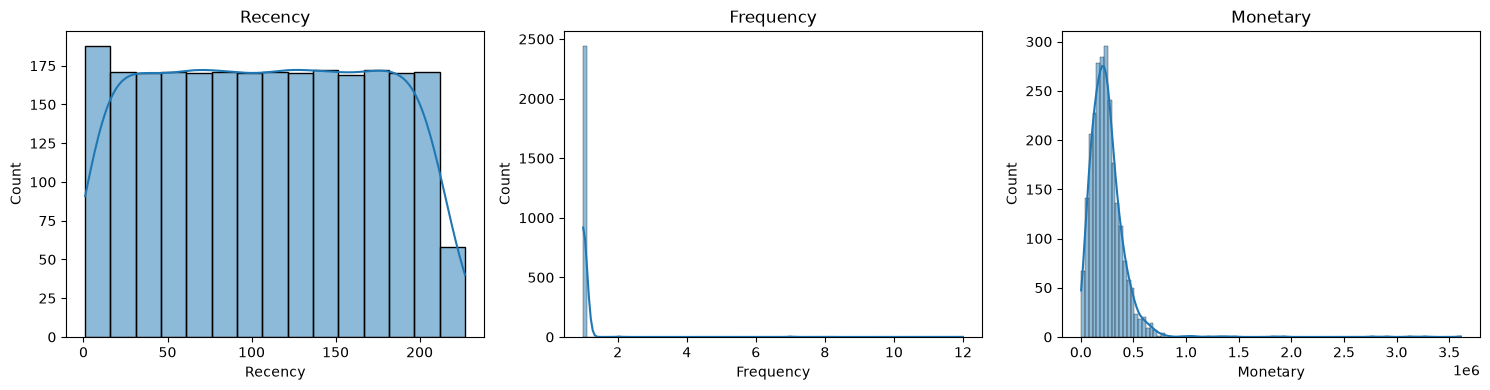

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(rfm_features["Recency"], kde=True, ax=axes[0])
axes[0].set_title("Recency")

sns.histplot(rfm_features["Frequency"], kde=True, ax=axes[1])
axes[1].set_title("Frequency")

sns.histplot(rfm_features["Monetary"], kde=True, ax=axes[2])
axes[2].set_title("Monetary")

plt.tight_layout()
plt.show()

In [13]:
rfm_log = rfm_features.copy()

rfm_log["Recency"] = np.log1p(rfm_log["Recency"])
rfm_log["Frequency"] = np.log1p(rfm_log["Frequency"])
rfm_log["Monetary"] = np.log1p(rfm_log["Monetary"])

rfm_log.head()

,Recency,Frequency,Monetary
0,5.036953,0.693147,12.461269
1,5.220356,0.693147,12.889801
2,4.615121,0.693147,12.836264
3,4.262680,0.693147,12.000689
4,4.488636,0.693147,12.535696


In [14]:
scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

print("RFM data standardized successfully.")

RFM data standardized successfully.


In [15]:
rfm_scaled = pd.DataFrame(
    rfm_scaled,
    columns=[
        "Recency",
        "Frequency",
        "Monetary"
    ]
)

rfm_scaled.head()

,Recency,Frequency,Monetary
0,0.684129,-0.082522,0.359721
1,0.885566,-0.082522,0.976351
2,0.220821,-0.082522,0.899315
3,-0.166274,-0.082522,-0.303024
4,0.081900,-0.082522,0.466818


In [16]:
inertia = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    inertia.append(kmeans.inertia_)

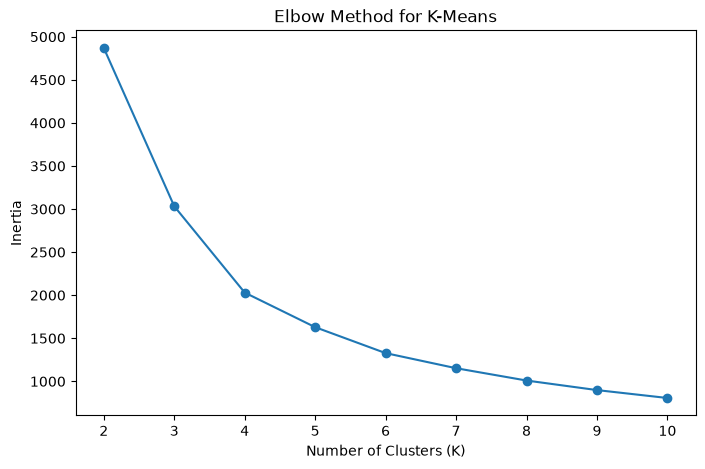

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    inertia,
    marker="o"
)

plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")

plt.show()

In [18]:
silhouette_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(rfm_scaled)

    score = silhouette_score(
        rfm_scaled,
        labels
    )

    silhouette_scores.append(score)

    print(
        "K =", k,
        "Silhouette Score =", round(score, 4)
    )

K = 2 Silhouette Score = 0.8729
K = 3 Silhouette Score = 0.4674
K = 4 Silhouette Score = 0.4395
K = 5 Silhouette Score = 0.3541
K = 6 Silhouette Score = 0.3602
K = 7 Silhouette Score = 0.3646
K = 8 Silhouette Score = 0.3474
K = 9 Silhouette Score = 0.352
K = 10 Silhouette Score = 0.3554


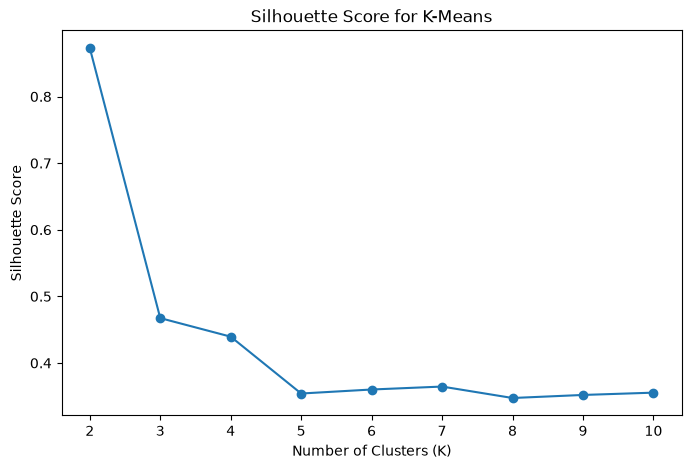

In [19]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

plt.show()

In [20]:
optimal_k = 2

print("Selected number of clusters:", optimal_k)

Selected number of clusters: 2


In [21]:
optimal_k = 4

print("Selected number of clusters:", optimal_k)

Selected number of clusters: 4


In [22]:
kmeans_model = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

kmeans_model.fit(rfm_scaled)

print("K-Means model trained successfully.")

K-Means model trained successfully.


In [23]:
cluster_labels = kmeans_model.predict(rfm_scaled)

cluster_labels[:10]

array([1, 1, 1, 1, 1, 1, 3, 1, 0, 1], dtype=int32)

In [24]:
rfm["Cluster"] = cluster_labels

rfm.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Total,RFM_Segment,Cluster
0,0025d7a1-81d7-4240-8807-4aed48f88cde,153,1,258142.0,2,1,4,214,7,Potential,1
1,00381394-0d27-43e1-aa0c-2105ea482b2b,184,1,396249.0,1,1,5,115,7,Potential,1
2,003c8473-1b85-445f-bcfb-948e6c9f8451,100,1,375593.0,3,1,5,315,9,Potential,1
3,004d5aa3-b784-4619-8e18-0411b8f90404,70,1,162866.0,4,1,2,412,7,Potential,1
4,0089210b-880d-4835-b385-14486458934b,88,1,278088.0,3,1,4,314,8,Potential,1


In [25]:
cluster_counts = rfm["Cluster"].value_counts().sort_index()

print(cluster_counts)

Cluster
0     403
1    1529
2      15
3     517
Name: count, dtype: int64


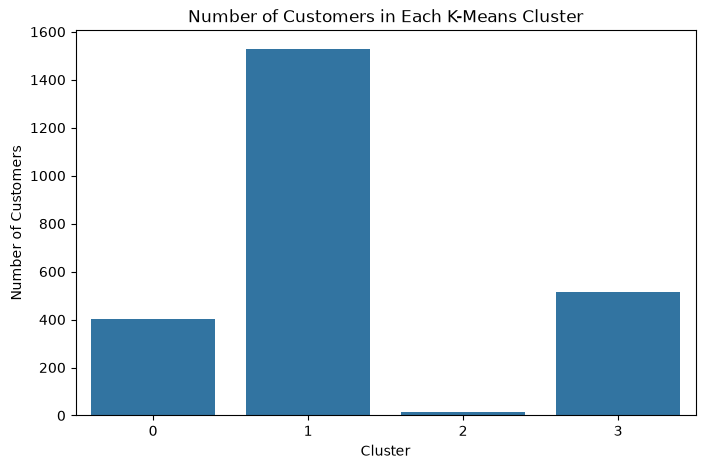

In [26]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=rfm,
    x="Cluster"
)

plt.title("Number of Customers in Each K-Means Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

plt.show()

In [27]:
cluster_summary = rfm.groupby("Cluster").agg(
    Customers=("CustomerID", "count"),
    AverageRecency=("Recency", "mean"),
    AverageFrequency=("Frequency", "mean"),
    AverageMonetary=("Monetary", "mean")
).round(2)

cluster_summary

,Customers,AverageRecency,AverageFrequency,AverageMonetary
Cluster,,,,
0,403,19.27,1.00,210311.25
1,1529,128.34,1.00,297517.17
2,15,213.80,7.93,1832034.47
3,517,116.19,1.00,89701.04


In [28]:

cluster_names = {
    0: "Potential Customers",
    1: "Inactive Customers",
    2: "Loyal Customers",
    3: "At-Risk Customers "
}

rfm["Segment"] = rfm["Cluster"].map(cluster_names)

In [29]:
rfm[
    [
        "CustomerID",
        "Recency",
        "Frequency",
        "Monetary",
        "Cluster",
        "Segment"
    ]
].head(20)

,CustomerID,Recency,Frequency,Monetary,Cluster,Segment
0,0025d7a1-81d7-4240-8807-4aed48f88cde,153,1,258142.0,1,Inactive Customers
1,00381394-0d27-43e1-aa0c-2105ea482b2b,184,1,396249.0,1,Inactive Customers
2,003c8473-1b85-445f-bcfb-948e6c9f8451,100,1,375593.0,1,Inactive Customers
3,004d5aa3-b784-4619-8e18-0411b8f90404,70,1,162866.0,1,Inactive Customers
4,0089210b-880d-4835-b385-14486458934b,88,1,278088.0,1,Inactive Customers
5,00d26b82-3d0d-49c7-9d15-e0dab6739ddd,154,1,447464.0,1,Inactive Customers
6,00e77c94-b376-4239-8ee0-a6b783d2ac94,96,1,111612.0,3,At-Risk Customers
7,0100f230-e005-4271-8ce6-3c30d088047d,36,1,471141.0,1,Inactive Customers
8,012de2cf-81ef-4b94-812f-7b1e7739b099,6,1,91173.0,0,Potential Customers
9,0130243b-f72a-4a4d-9481-2a1ad6bb3c36,70,1,316870.0,1,Inactive Customers


In [30]:
segment_summary = rfm.groupby("Segment").agg(
    Customers=("CustomerID", "count"),
    AverageRecency=("Recency", "mean"),
    AverageFrequency=("Frequency", "mean"),
    AverageMonetary=("Monetary", "mean")
).round(2)

segment_summary

,Customers,AverageRecency,AverageFrequency,AverageMonetary
Segment,,,,
At-Risk Customers,517,116.19,1.00,89701.04
Inactive Customers,1529,128.34,1.00,297517.17
Loyal Customers,15,213.80,7.93,1832034.47
Potential Customers,403,19.27,1.00,210311.25


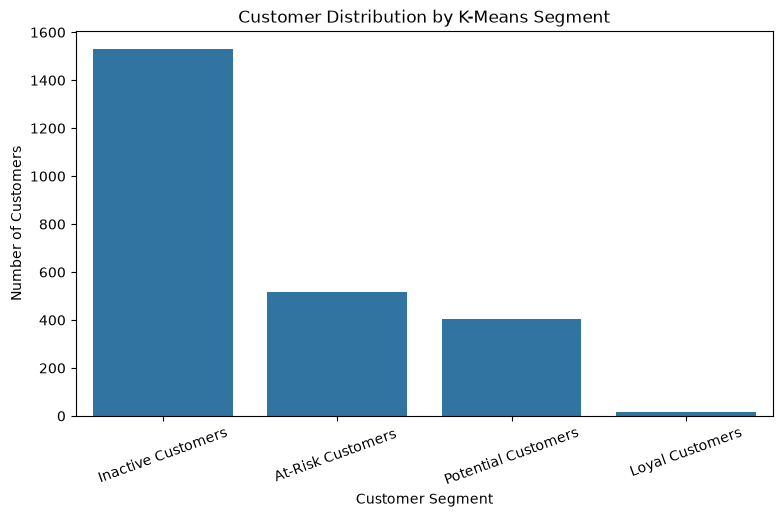

In [31]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=rfm,
    x="Segment",
    order=rfm["Segment"].value_counts().index
)

plt.title("Customer Distribution by K-Means Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=20)

plt.show()

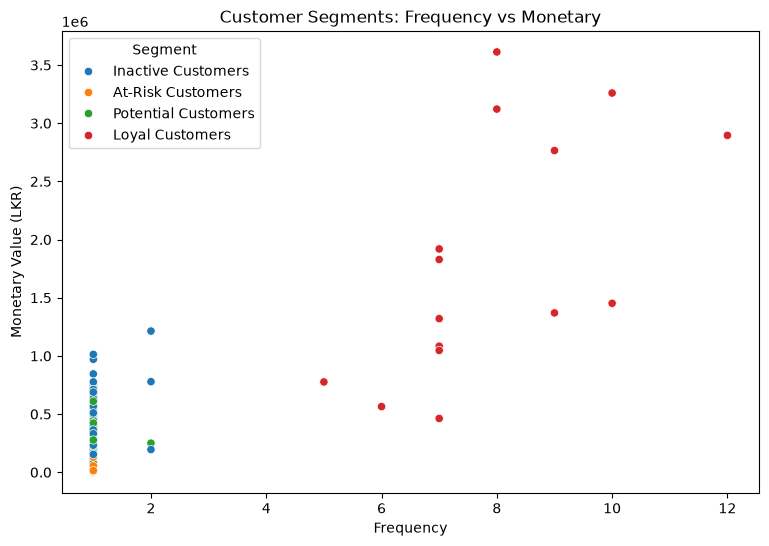

In [32]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Segment"
)

plt.title("Customer Segments: Frequency vs Monetary")
plt.xlabel("Frequency")
plt.ylabel("Monetary Value (LKR)")

plt.show()

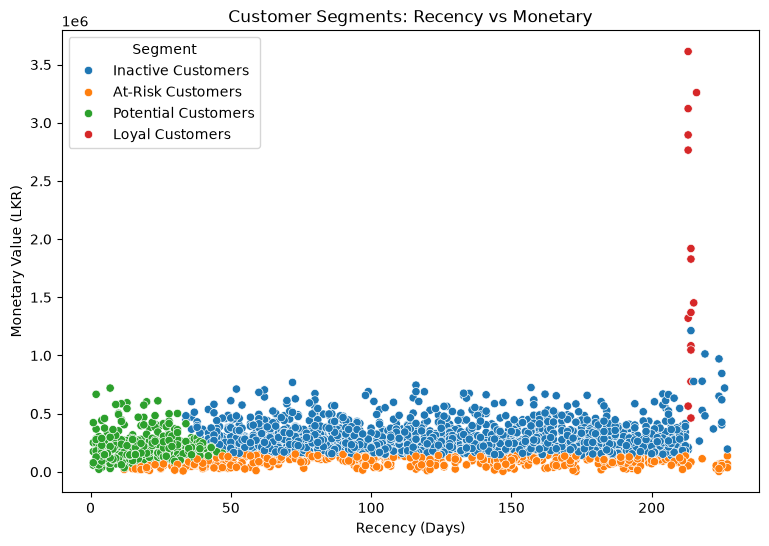

In [33]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rfm,
    x="Recency",
    y="Monetary",
    hue="Segment"
)

plt.title("Customer Segments: Recency vs Monetary")
plt.xlabel("Recency (Days)")
plt.ylabel("Monetary Value (LKR)")

plt.show()

In [34]:
final_silhouette = silhouette_score(
    rfm_scaled,
    rfm["Cluster"]
)

print(
    "Final Silhouette Score:",
    round(final_silhouette, 4)
)

Final Silhouette Score: 0.4395


In [36]:
kmeans_file = "C:/Users/RSCH/Desktop/DWD/Final project/Retail-Intelligence-Platform/datasets/customer_segments.xlsx"

rfm.to_excel(
    kmeans_file,
    sheet_name="Customer_Segments",
    index=False
)

print("K-Means customer segmentation saved successfully.")

K-Means customer segmentation saved successfully.


In [37]:
print("======================================")
print("K-MEANS CUSTOMER SEGMENTATION")
print("======================================")

print("Total Customers:", rfm["CustomerID"].nunique())
print("Number of Clusters:", optimal_k)
print(
    "Silhouette Score:",
    round(final_silhouette, 4)
)

print("\nCustomer Distribution:")
print(rfm["Segment"].value_counts())

print("\nCluster Summary:")
print(segment_summary)

print("======================================")

K-MEANS CUSTOMER SEGMENTATION
Total Customers: 2464
Number of Clusters: 4
Silhouette Score: 0.4395

Customer Distribution:
Segment
Inactive Customers     1529
At-Risk Customers       517
Potential Customers     403
Loyal Customers          15
Name: count, dtype: int64

Cluster Summary:
                     Customers  AverageRecency  AverageFrequency  \
Segment                                                            
At-Risk Customers          517          116.19              1.00   
Inactive Customers        1529          128.34              1.00   
Loyal Customers             15          213.80              7.93   
Potential Customers        403           19.27              1.00   

                     AverageMonetary  
Segment                               
At-Risk Customers           89701.04  
Inactive Customers         297517.17  
Loyal Customers           1832034.47  
Potential Customers        210311.25  


In [38]:

cluster_summary = rfm.groupby("Cluster").agg(
    Customers=("CustomerID", "nunique"),
    AverageRecency=("Recency", "mean"),
    AverageFrequency=("Frequency", "mean"),
    AverageMonetary=("Monetary", "mean")
).round(2)

print(cluster_summary)



         Customers  AverageRecency  AverageFrequency  AverageMonetary
Cluster                                                              
0              403           19.27              1.00        210311.25
1             1529          128.34              1.00        297517.17
2               15          213.80              7.93       1832034.47
3              517          116.19              1.00         89701.04


In [ ]:
from sklearn.cluster import KMeans

optimal_k = 4

kmeans_model = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

kmeans_model.fit(rfm_scaled)

print("Final K-Means model trained.")
print("Number of clusters:", optimal_k)

Final K-Means model trained.
Number of clusters: 4


In [40]:
import joblib

joblib.dump(
    kmeans_model,
    "../backend/ml/segmentation/kmeans_model.pkl"
)

joblib.dump(
    scaler,
    "../backend/ml/segmentation/rfm_scaler.pkl"
)

print("K-Means model saved successfully.")
print("RFM scaler saved successfully.")

K-Means model saved successfully.
RFM scaler saved successfully.


In [41]:
cluster_labels = {
    0: "Potential Customers",
    1: "Inactive Customers",
    2: "Loyal Customers",
    3: "At-Risk Customers"
}

   
   
joblib.dump(
    cluster_labels,
    "../backend/ml/segmentation/cluster_labels.pkl"
)

print("Cluster labels saved successfully.")

Cluster labels saved successfully.
